In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv('crop_yield.csv')

# Drop categorical objects and select only numerical features + target
# We will use numerical features: Crop_Year, Area, Production, Annual_Rainfall, Fertilizer, Pesticide
numerical_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

X = df[numerical_cols]
y = df['Yield']

# Train-test split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale numerical features so they have mean=0 and variance=1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data loaded, filtered for numericals only, and scaled successfully!")
print(f"Training features shape: {X_train_scaled.shape}")

Data loaded, filtered for numericals only, and scaled successfully!
Training features shape: (15751, 6)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv('crop_yield.csv')

# Separate features and target
X = df.drop(columns=['Yield'])
y = df['Yield']

# Define categorical and numerical columns
categorical_cols = ['Crop', 'Season', 'State']
numerical_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

# Train-test split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Set up ColumnTransformer to scale numbers and one-hot encode categories
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit and transform training data, transform testing data
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Data successfully preprocessed with One-Hot Encoding!")
print(f"New feature matrix shape (Training): {X_train_encoded.shape}")

Data successfully preprocessed with One-Hot Encoding!
New feature matrix shape (Training): (15751, 97)


In [ ]:
from sklearn.linear_model import LinearRegression

# Initialize and train
lr_model = LinearRegression()
lr_model.fit(X_train_encoded, y_train)

# Predict & Evaluate
y_pred_lr = lr_model.predict(X_test_encoded)

print("=== Linear Regression (with Categoricals) ===")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_lr):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_lr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred_lr):.4f}")

=== Linear Regression (with Categoricals) ===
MAE:  62.9800
MSE:  158461.9276
RMSE: 398.0728
R²:   0.8022


In [ ]:
from sklearn.linear_model import Ridge

# Initialize and train
ridge_model = Ridge(alpha=2.0)
ridge_model.fit(X_train_encoded, y_train)

# Predict & Evaluate
y_pred_ridge = ridge_model.predict(X_test_encoded)

print("=== Ridge Regression (with Categoricals) ===")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_ridge):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_ridge):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_ridge)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred_ridge):.4f}")

=== Ridge Regression (with Categoricals) ===
MAE:  63.4363
MSE:  157486.0939
RMSE: 396.8452
R²:   0.8034


In [ ]:
from sklearn.linear_model import BayesianRidge

# Initialize and train
bayes_model = BayesianRidge()
bayes_model.fit(X_train_encoded, y_train)

# Predict & Evaluate
y_pred_bayes = bayes_model.predict(X_test_encoded)

print("=== Bayesian Ridge Regression (with Categoricals) ===")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_bayes):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_bayes):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_bayes)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred_bayes):.4f}")

=== Bayesian Ridge Regression (with Categoricals) ===
MAE:  63.0396
MSE:  158319.7917
RMSE: 397.8942
R²:   0.8024


In [ ]:
from sklearn.linear_model import HuberRegressor

# Initialize and train
robust_model = HuberRegressor(max_iter=2000)
robust_model.fit(X_train_encoded, y_train)

# Predict & Evaluate
y_pred_robust = robust_model.predict(X_test_encoded)

print("=== Robust Regression (with Categoricals) ===")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_robust):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_robust):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_robust)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred_robust):.4f}")

=== Robust Regression (with Categoricals) ===
MAE:  35.4966
MSE:  182073.2326
RMSE: 426.7004
R²:   0.7728


In [ ]:
from sklearn.svm import SVR

# Initialize and train (Note: SVR can take longer to train on wide one-hot encoded matrices)
svr_model = SVR(kernel='rbf')
svr_model.fit(X_train_encoded, y_train)

# Predict & Evaluate
y_pred_svr = svr_model.predict(X_test_encoded)

print("=== Support Vector Regressor (SVR) (with Categoricals) ===")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_svr):.4f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred_svr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred_svr):.4f}")

=== Support Vector Regressor (SVR) (with Categoricals) ===
MAE:  76.8733
MSE:  805003.0860
RMSE: 897.2196
R²:   -0.0047


In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Let's create an engineered copy of the training/testing features
df_eng = df.copy()

# Feature Engineering: Create ratio columns to avoid raw magnitudes
df_eng['Fertilizer_per_Area'] = df_eng['Fertilizer'] / (df_eng['Area'] + 1e-5)
df_eng['Pesticide_per_Area'] = df_eng['Pesticide'] / (df_eng['Area'] + 1e-5)
df_eng['Rainfall_per_Area'] = df_eng['Annual_Rainfall'] / (df_eng['Area'] + 1e-5)

# Update numerical columns list
numerical_cols_eng = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall',
                      'Fertilizer', 'Pesticide', 'Fertilizer_per_Area',
                      'Pesticide_per_Area', 'Rainfall_per_Area']

X_eng = df_eng.drop(columns=['Yield'])
y_eng = df_eng['Yield']

# Re-split with engineered features
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

# Preprocessor for engineered dataset
preprocessor_eng = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols_eng),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

X_train_encoded_eng = preprocessor_eng.fit_transform(X_train_e)
X_test_encoded_eng = preprocessor_eng.transform(X_test_e)

# Train Linear SVR (much better suited for high-dimensional sparse data)
svr_linear = SVR(kernel='linear', C=10.0)
svr_linear.fit(X_train_encoded_eng, y_train_e)
y_pred_svr_lin = svr_linear.predict(X_test_encoded_eng)

print("=== Linear SVR Results (with Feature Engineering) ===")
print(f"MAE:  {mean_absolute_error(y_test_e, y_pred_svr_lin):.4f}")
print(f"MSE:  {mean_squared_error(y_test_e, y_pred_svr_lin):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_e, y_pred_svr_lin)):.4f}")
print(f"R²:   {r2_score(y_test_e, y_pred_svr_lin):.4f}")

=== Linear SVR Results (with Feature Engineering) ===
MAE:  52.4290
MSE:  427233.7054
RMSE: 653.6312
R²:   0.4668


In [ ]:
from sklearn.linear_model import HuberRegressor

# Apply log-transformation to target to reduce long-tail skewness
y_train_log = np.log1p(y_train_e)
y_test_log = np.log1p(y_test_e)

# Train Huber Regressor on log-transformed target with an optimized epsilon
robust_opt = HuberRegressor(epsilon=1.35, max_iter=3000)
robust_opt.fit(X_train_encoded_eng, y_train_log)

# Predict in log space, then convert back using expm1()
y_pred_log = robust_opt.predict(X_test_encoded_eng)
y_pred_robust_opt = np.expm1(y_pred_log)

print("=== Optimized Robust Regression Results ===")
print(f"MAE:  {mean_absolute_error(y_test_e, y_pred_robust_opt):.4f}")
print(f"MSE:  {mean_squared_error(y_test_e, y_pred_robust_opt):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_e, y_pred_robust_opt)):.4f}")
print(f"R²:   {r2_score(y_test_e, y_pred_robust_opt):.4f}")

=== Optimized Robust Regression Results ===
MAE:  30.4336
MSE:  138476.8351
RMSE: 372.1248
R²:   0.8272


In [ ]:
from sklearn.linear_model import Ridge

alphas = [0.1, 1.0, 10.0, 100.0]
best_alpha = None
best_r2 = -float('inf')
best_preds = None

for a in alphas:
    ridge_grid = Ridge(alpha=a)
    ridge_grid.fit(X_train_encoded_eng, y_train_e)
    preds = ridge_grid.predict(X_test_encoded_eng)
    score = r2_score(y_test_e, preds)

    if score > best_r2:
        best_r2 = score
        best_alpha = a
        best_preds = preds

print(f"=== Optimized Ridge Regression (Best Alpha: {best_alpha}) ===")
print(f"MAE:  {mean_absolute_error(y_test_e, best_preds):.4f}")
print(f"MSE:  {mean_squared_error(y_test_e, best_preds):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_e, best_preds)):.4f}")
print(f"R²:   {best_r2:.4f}")

=== Optimized Ridge Regression (Best Alpha: 10.0) ===
MAE:  69.1509
MSE:  154199.3164
RMSE: 392.6822
R²:   0.8075


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert continuous Yield into binary classification target (1 if above median, else 0)
median_yield = df['Yield'].median()
y_class = (df['Yield'] > median_yield).astype(int)
X = df.drop(columns=['Yield'])

# Define columns
categorical_cols = ['Crop', 'Season', 'State']
numerical_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42)

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
print("Data preprocessed and converted for classification successfully!")

Data preprocessed and converted for classification successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Initialize and train
log_reg = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
log_reg.fit(X_train_enc, y_train)
y_pred = log_reg.predict(X_test_enc)

# Evaluation Metrics
print("=== Logistic Regression Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== Logistic Regression Results ===
Accuracy:  0.8542
Precision: 0.8718
Recall:    0.8292
F1-Score:  0.8500


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train
dt_clf = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_clf.fit(X_train_enc, y_train)
y_pred = dt_clf.predict(X_test_enc)

print("=== Decision Tree Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== Decision Tree Results ===
Accuracy:  0.9096
Precision: 0.9397
Recall:    0.8746
F1-Score:  0.9060


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski')
knn.fit(X_train_enc, y_train)
y_pred = knn.predict(X_test_enc)

print("=== KNN Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== KNN Results ===
Accuracy:  0.9200
Precision: 0.9282
Recall:    0.9097
F1-Score:  0.9189


In [ ]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train
nb = GaussianNB()
nb.fit(X_train_enc, y_train)
y_pred = nb.predict(X_test_enc)

print("=== Naive Bayes Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== Naive Bayes Results ===
Accuracy:  0.8311
Precision: 0.8020
Recall:    0.8776
F1-Score:  0.8381


In [ ]:
from sklearn.svm import SVC

# Initialize and train
svm_clf = SVC(kernel='linear', C=20 random_state=42)
svm_clf.fit(X_train_enc, y_train)
y_pred = svm_clf.predict(X_test_enc)

print("=== SVM Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== SVM Results ===
Accuracy:  0.8410
Precision: 0.8414
Recall:    0.8389
F1-Score:  0.8401


In [ ]:
from sklearn.neural_network import MLPClassifier

# Initialize and train
mlp = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42)
mlp.fit(X_train_enc, y_train)
y_pred = mlp.predict(X_test_enc)

print("=== Neural Network Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

=== Neural Network Results ===
Accuracy:  0.9317
Precision: 0.9370
Recall:    0.9250
F1-Score:  0.9310


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


=== Comparative Performance Analysis ===
        Model  Accuracy  Precision   Recall  F1-Score
 Logistic Reg  0.854241   0.871850 0.829169  0.849974
Decision Tree  0.909599   0.939726 0.874554  0.905969
          KNN  0.920010   0.928200 0.909740  0.918877
  Naive Bayes  0.831133   0.801957 0.877613  0.838081
          SVM  0.841036   0.841432 0.838858  0.840143
   Neural Net  0.931691   0.936983 0.925038  0.930973


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


<Figure size 1000x500 with 0 Axes>

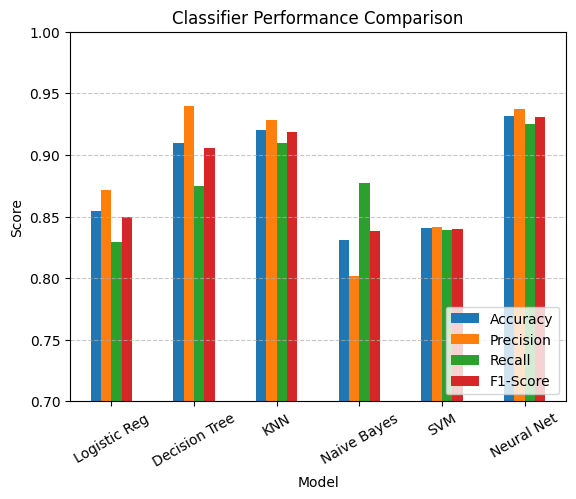

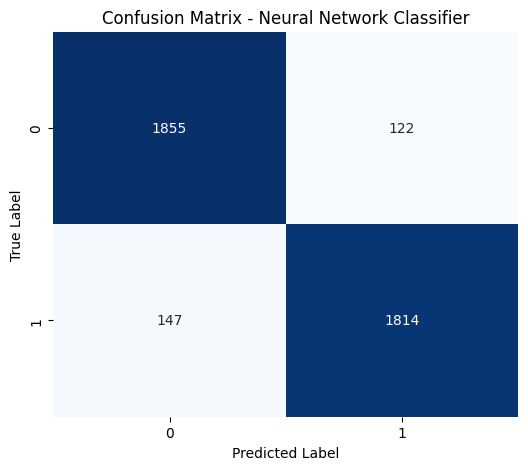

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Re-run all models quickly to gather predictions for comparison
eval_models = {
    "Logistic Reg": LogisticRegression(max_iter=1000, C=1.0, random_state=42).fit(X_train_enc, y_train).predict(X_test_enc),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42).fit(X_train_enc, y_train).predict(X_test_enc),
    "KNN": KNeighborsClassifier(n_neighbors=5).fit(X_train_enc, y_train).predict(X_test_enc),
    "Naive Bayes": GaussianNB().fit(X_train_enc, y_train).predict(X_test_enc),
    "SVM": SVC(kernel='linear', random_state=42).fit(X_train_enc, y_train).predict(X_test_enc),
    "Neural Net": MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42).fit(X_train_enc, y_train).predict(X_test_enc)
}

# Compile Metrics Table
metrics_data = []
for name, preds in eval_models.items():
    metrics_data.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

metrics_df = pd.DataFrame(metrics_data)
print("=== Comparative Performance Analysis ===")
print(metrics_df.to_string(index=False))

# 1. Graphical Comparison Chart
plt.figure(figsize=(10, 5))
metrics_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', ylim=(0.7, 1.0))
plt.title('Classifier Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Confusion Matrix Heatmap (using Neural Network predictions)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, eval_models["Neural Net"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Neural Network Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

=== Regression Comparative Performance Analysis ===
         Model       MAE           MSE       RMSE  R² Score
    Linear Reg 62.980046 158461.927585 398.072767  0.802229
         Ridge 68.969727 154190.693626 392.671228  0.807560
Bayesian Ridge 63.039649 158319.791692 397.894197  0.802406
Robust (Huber) 30.309343 137755.706042 371.154558  0.828072
    Linear SVR 52.430213 427234.446416 653.631736  0.466783


/tmp/ipykernel_891/3302636966.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_metrics_df, x='Model', y='R² Score', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_891/3302636966.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_metrics_df, x='Model', y='RMSE', ax=axes[1], palette='Reds_d')


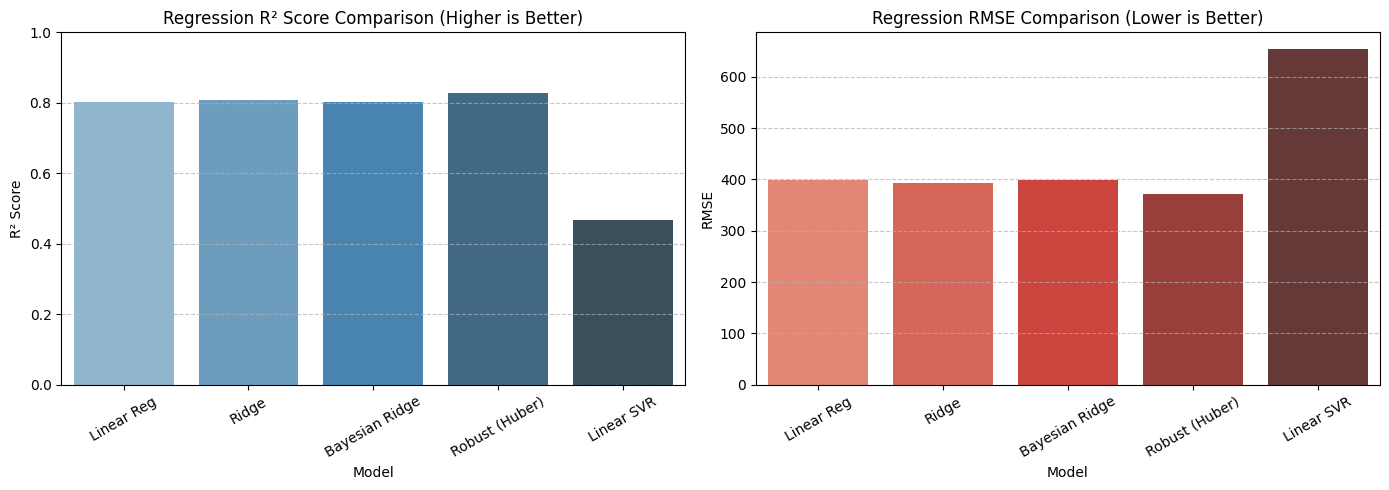

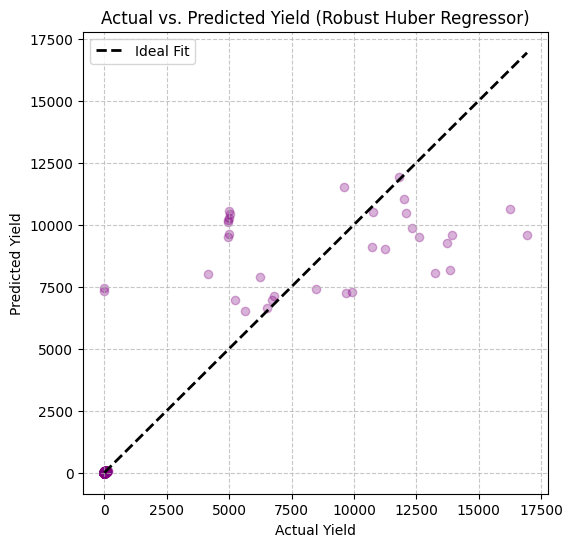

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, BayesianRidge, HuberRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Prepare Data & Preprocessing
df = pd.read_csv('crop_yield.csv')
X = df.drop(columns=['Yield'])
y = df['Yield']

categorical_cols = ['Crop', 'Season', 'State']
numerical_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
y_train_log = np.log1p(y_train)

# 2. Train and Collect Predictions from Regression Models
reg_models = {
    "Linear Reg": LinearRegression().fit(X_train_enc, y_train).predict(X_test_enc),
    "Ridge": Ridge(alpha=10.0).fit(X_train_enc, y_train).predict(X_test_enc),
    "Bayesian Ridge": BayesianRidge().fit(X_train_enc, y_train).predict(X_test_enc),
    "Robust (Huber)": np.expm1(HuberRegressor(epsilon=1.35, max_iter=3000).fit(X_train_enc, y_train_log).predict(X_test_enc)),
    "Linear SVR": SVR(kernel='linear', C=10.0).fit(X_train_enc, y_train).predict(X_test_enc)
}

# 3. Compile Metrics Table
reg_metrics_data = []
for name, preds in reg_models.items():
    reg_metrics_data.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, preds),
        "MSE": mean_squared_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R² Score": r2_score(y_test, preds)
    })

reg_metrics_df = pd.DataFrame(reg_metrics_data)
print("=== Regression Comparative Performance Analysis ===")
print(reg_metrics_df.to_string(index=False))

# 4. Graphical Comparison Chart ($R^2$ Score & RMSE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot for R² Score
sns.barplot(data=reg_metrics_df, x='Model', y='R² Score', ax=axes[0], palette='Blues_d')
axes[0].set_title('Regression R² Score Comparison (Higher is Better)')
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Bar plot for RMSE
sns.barplot(data=reg_metrics_df, x='Model', y='RMSE', ax=axes[1], palette='Reds_d')
axes[1].set_title('Regression RMSE Comparison (Lower is Better)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 5. Actual vs. Predicted Scatter Plot (Regression Equivalent of Confusion Matrix)
# Using our best performing model: Robust (Huber) Regressor
plt.figure(figsize=(6, 6))
best_preds = reg_models["Robust (Huber)"]
plt.scatter(y_test, best_preds, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Ideal Fit')
plt.title('Actual vs. Predicted Yield (Robust Huber Regressor)')
plt.xlabel('Actual Yield')
plt.ylabel('Predicted Yield')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


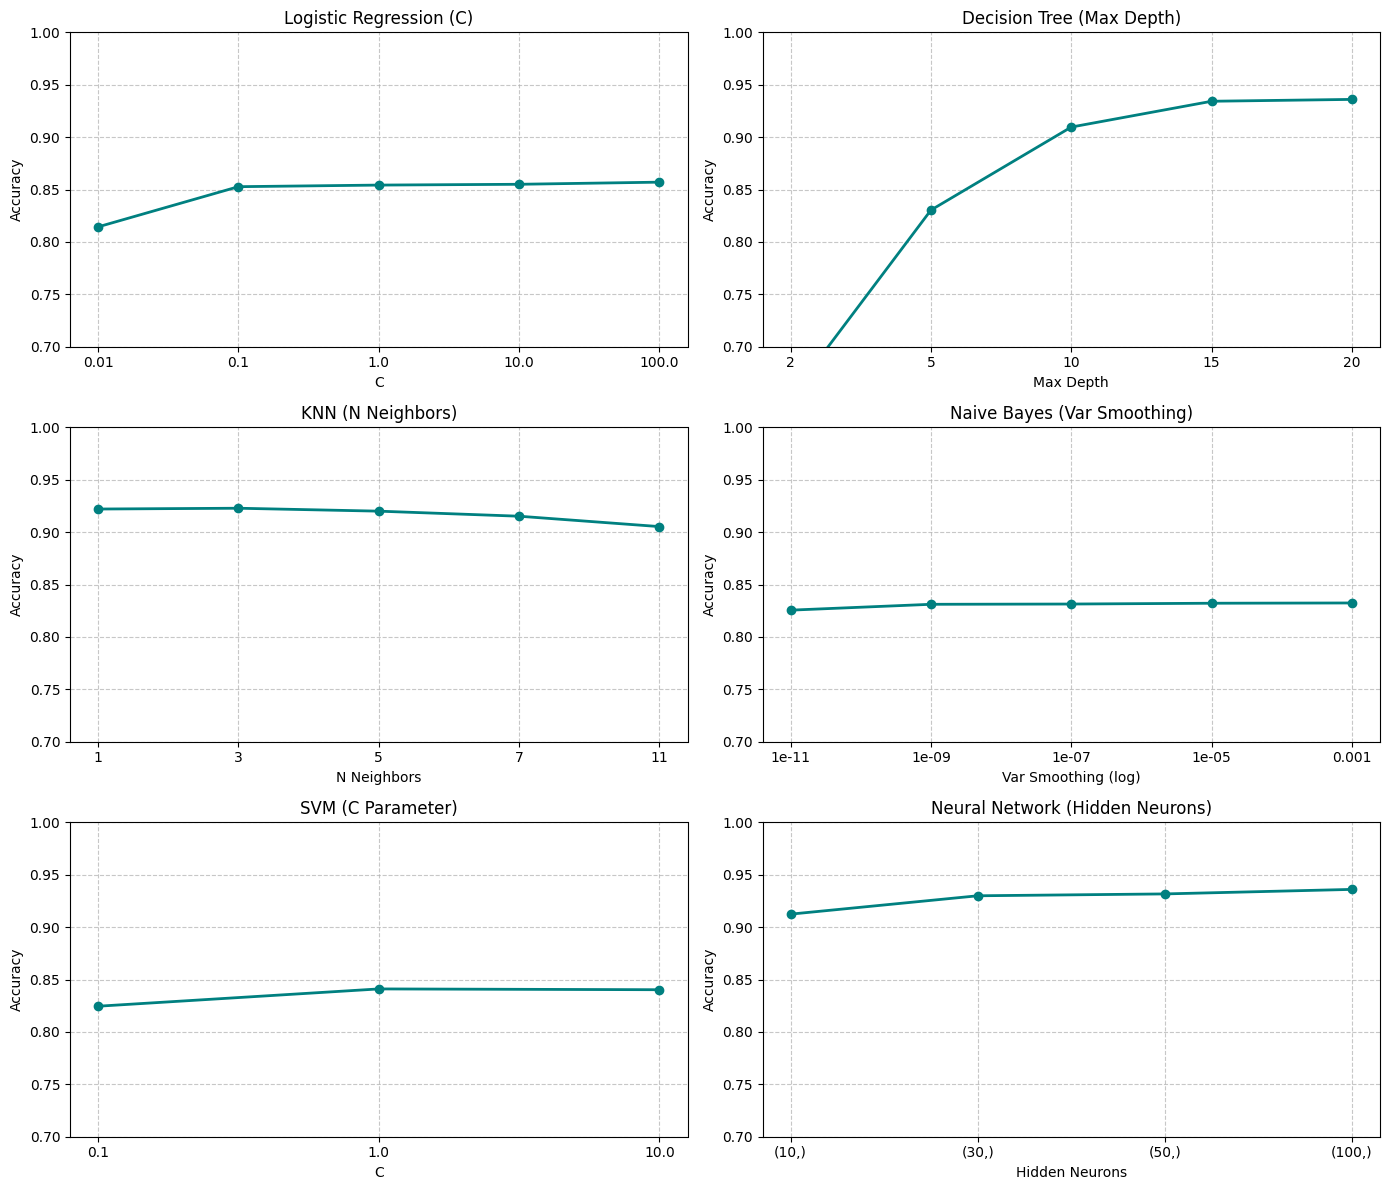

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# 1. Load and Preprocess Data
df = pd.read_csv('crop_yield.csv')
median_yield = df['Yield'].median()
y_class = (df['Yield'] > median_yield).astype(int)
X = df.drop(columns=['Yield'])

categorical_cols = ['Crop', 'Season', 'State']
numerical_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

# 2. Define Hyperparameters to Test for Each Model
tuning_experiments = {
    "Logistic Regression (C)": {
        "param_name": "C",
        "values": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model_func": lambda val: LogisticRegression(C=val, max_iter=1000, random_state=42)
    },
    "Decision Tree (Max Depth)": {
        "param_name": "Max Depth",
        "values": [2, 5, 10, 15, 20],
        "model_func": lambda val: DecisionTreeClassifier(max_depth=val, random_state=42)
    },
    "KNN (N Neighbors)": {
        "param_name": "N Neighbors",
        "values": [1, 3, 5, 7, 11],
        "model_func": lambda val: KNeighborsClassifier(n_neighbors=val)
    },
    "Naive Bayes (Var Smoothing)": {
        "param_name": "Var Smoothing (log)",
        "values": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3],
        "model_func": lambda val: GaussianNB(var_smoothing=val)
    },
    "SVM (C Parameter)": {
        "param_name": "C",
        "values": [0.1, 1.0, 10.0],
        "model_func": lambda val: SVC(kernel='linear', C=val, random_state=42)
    },
    "Neural Network (Hidden Neurons)": {
        "param_name": "Hidden Neurons",
        "values": [(10,), (30,), (50,), (100,)],
        "model_func": lambda val: MLPClassifier(hidden_layer_sizes=val, max_iter=300, random_state=42)
    }
}

# 3. Run Tuning & Plot Graphs
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, (model_name, exp) in enumerate(tuning_experiments.items()):
    scores = []
    for val in exp["values"]:
        clf = exp["model_func"](val)
        clf.fit(X_train_enc, y_train)
        preds = clf.predict(X_test_enc)
        scores.append(accuracy_score(y_test, preds))

    # Plotting individual model curves
    # For neural network, convert tuple to string for x-axis plotting
    x_labels = [str(v) for v in exp["values"]]

    axes[idx].plot(x_labels, scores, marker='o', linestyle='-', color='teal', linewidth=2)
    axes[idx].set_title(model_name)
    axes[idx].set_xlabel(exp["param_name"])
    axes[idx].set_ylabel("Accuracy")
    axes[idx].set_ylim(0.7, 1.0)
    axes[idx].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()